# Notebook 1: Images and k-space

*Part of MRI Reconstruction from k-space to Deep Learning: A Hands-on Introduction*

An MRI scanner never takes a picture directly. It measures k-space: the spatial frequencies of the object. The image you see is computed from those measurements. Every reconstruction method in this module, from the simple Fourier transform to deep learning, starts here.

**Learning objectives.** By the end of this notebook you will be able to:

1. Compute k-space from an image, and an image from k-space, with a centered 2D Fourier transform.
2. Explain what a single point of k-space contributes to the image.
3. Predict which image features come from the center and which from the edges of k-space.
4. Explain why one corrupted k-space sample affects the whole image.

**Prerequisites:** basic Python and NumPy, complex numbers, and the idea of a Fourier transform. No MRI background is needed.

**Time:** about 60–75 minutes.

**How to use this notebook:** run the cells from top to bottom. Before each experiment there is a Predict question. Write down your guess *before* running the cell, then check it. Guessing wrong and finding out why is how this material sticks.

## 1. Setup

Everything here runs in Google Colab or any Python 3 environment with NumPy, Matplotlib and scikit-image (all preinstalled in Colab).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import resize, rotate

plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(0)  # fixed seed so everyone sees the same results

### Helper functions

NumPy's FFT puts the zero frequency in the *corner* of the array. MRI convention puts it in the *center* of k-space, so we wrap the FFT in `fftshift`/`ifftshift`. We also use `norm="ortho"`, which keeps the total signal energy the same in both domains (Parseval's theorem). These two helpers, `fft2c` and `ifft2c` ("c" for centered), are used in every notebook of this module.

In [2]:
def fft2c(image):
    """Centered, orthonormal 2D FFT: image -> k-space."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image), norm="ortho"))


def ifft2c(kspace):
    """Centered, orthonormal inverse 2D FFT: k-space -> image."""
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace), norm="ortho"))


def log_mag(kspace):
    """Log-scaled magnitude, so both the bright center and the faint edges of k-space are visible."""
    mag = np.abs(kspace)
    return np.log10(mag / mag.max() + 1e-6)  # 0 at the brightest point, about -6 for the faintest


def show(images, titles, cmap="gray", vmin=None, vmax=None):
    """Show images side by side."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 2. The object: a digital phantom

We use the Shepp-Logan phantom, a simple model of a head cross-section made of ellipses. It was designed in 1974 for testing CT reconstruction and is still a standard test object. Using a phantom means we know the *true* image exactly, so we can measure every error, and the notebook needs no data download or data agreement.

Image size: (256, 256), intensity range 0.00 to 1.00


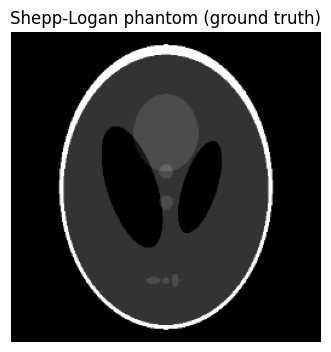

In [3]:
N = 256
image = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)

print(f"Image size: {image.shape}, intensity range {image.min():.2f} to {image.max():.2f}")
show([image], ["Shepp-Logan phantom (ground truth)"])

## 3. What the scanner measures: k-space

In MRI, magnetic field gradients give each position in the body a slightly different precession frequency and phase. The signal the coil receives at any moment is the sum over the whole slice:

$$ s(k_x, k_y) = \iint m(x, y)\, e^{-i 2\pi (k_x x + k_y y)}\, dx\, dy $$

where $m(x, y)$ is the image we want. This is exactly the 2D Fourier transform of the image. By changing the gradients over time, the scanner visits different points $(k_x, k_y)$, usually one horizontal line per repetition. The full grid of measurements is called k-space.

So in simulation, *measuring* an image means taking its Fourier transform, and *reconstructing* it means taking the inverse.

> **Predict:** Most objects are made of large smooth regions plus a few sharp edges. Where in k-space do you expect most of the signal to be: near the center (low frequencies) or near the edges (high frequencies)?

k-space is complex128 with shape (256, 256)


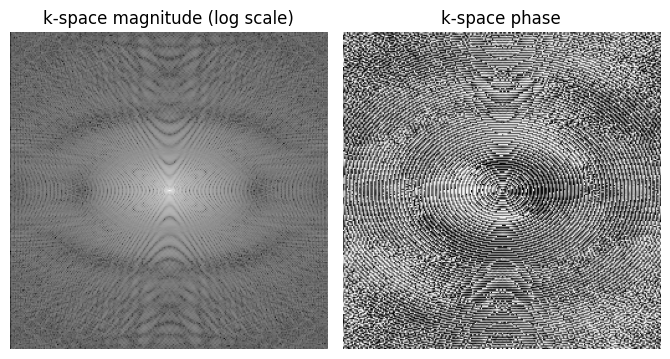

In [4]:
kspace = fft2c(image)

print(f"k-space is {kspace.dtype} with shape {kspace.shape}")
show(
    [log_mag(kspace), np.angle(kspace)],
    ["k-space magnitude (log scale)", "k-space phase"],
    cmap="gray",
)

**What you see:**

- The magnitude is very bright at the center and falls off quickly towards the edges. Most of the signal is at low spatial frequencies.
- k-space is complex. The phase looks like noise, but it carries essential information about *where* things are (you will test this in Exercise 2).
- k-space does not look like the object at all. Every k-space point depends on every pixel of the image.

Now check that the inverse transform gives the image back exactly.

In [5]:
recon = ifft2c(kspace)

print(f"Largest imaginary part in the reconstruction: {np.abs(recon.imag).max():.1e}")
print(f"Largest reconstruction error: {np.abs(recon.real - image).max():.1e}")
print(f"Energy in image:   {np.sum(np.abs(image) ** 2):.4f}")
print(f"Energy in k-space: {np.sum(np.abs(kspace) ** 2):.4f}  (equal: Parseval's theorem)")

Largest imaginary part in the reconstruction: 3.0e-16
Largest reconstruction error: 4.4e-16
Energy in image:   3852.9499
Energy in k-space: 3852.9499  (equal: Parseval's theorem)


With full k-space, reconstruction is trivial and exact (errors around $10^{-15}$ are just floating-point rounding). The rest of this module is about what happens when k-space is incomplete, because measuring less of it is how scans are made faster.

Real scanner images are complex-valued, so from now on we display the magnitude `np.abs(...)` of reconstructions, as scanners do.

## 4. Each k-space point is a stripe pattern

To understand k-space, look at what a single point of it contributes to the image.

> **Predict:** If k-space contains only one non-zero point, slightly to the right of the center, what will the image look like?

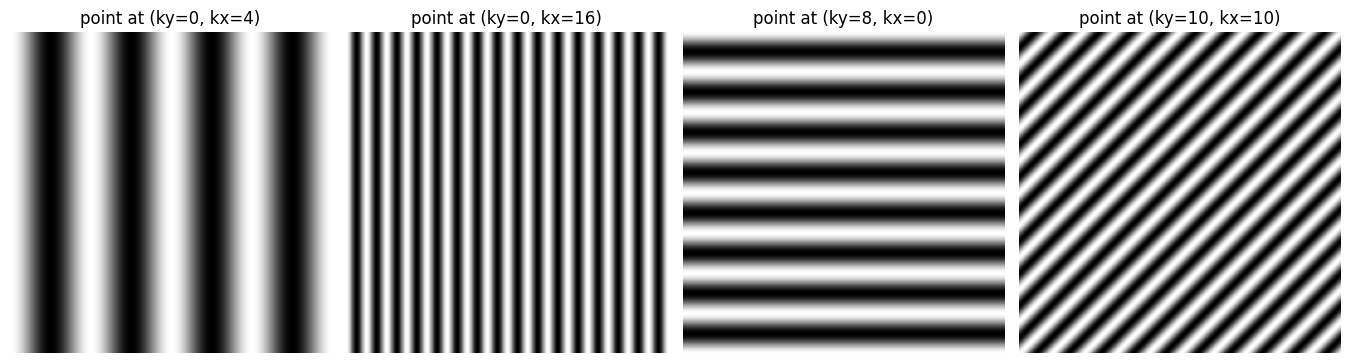

In [6]:
def single_point_image(ky, kx):
    """Image produced by a k-space that is zero everywhere except one point (ky, kx) from the center."""
    k = np.zeros((N, N), dtype=complex)
    k[N // 2 + ky, N // 2 + kx] = N  # scaled so the stripes have amplitude 1
    return ifft2c(k).real


offsets = [(0, 4), (0, 16), (8, 0), (10, 10)]
show(
    [single_point_image(ky, kx) for ky, kx in offsets],
    [f"point at (ky={ky}, kx={kx})" for ky, kx in offsets],
    vmin=-1, vmax=1,
)

Each k-space point is one stripe pattern (a 2D sinusoid) across the *whole* image.

- **Distance from the center** sets the stripe frequency: further out means finer stripes.
- **Direction from the center** sets the stripe orientation.
- The k-space value (a complex number) sets how strong the stripes are (magnitude) and where they are shifted (phase).

An MR image is the sum of 65,536 of these patterns, one for each k-space point. This explains everything that follows.

## 5. The center and the edges of k-space

> **Predict:** We split k-space into a small central disk (about 1% of the points) and everything else. Which part gives you the overall shapes and brightness of the object, and which gives you the edges? Roughly what share of the signal energy is in the small central disk?

Central disk: 1.2% of k-space points, 75.5% of the signal energy


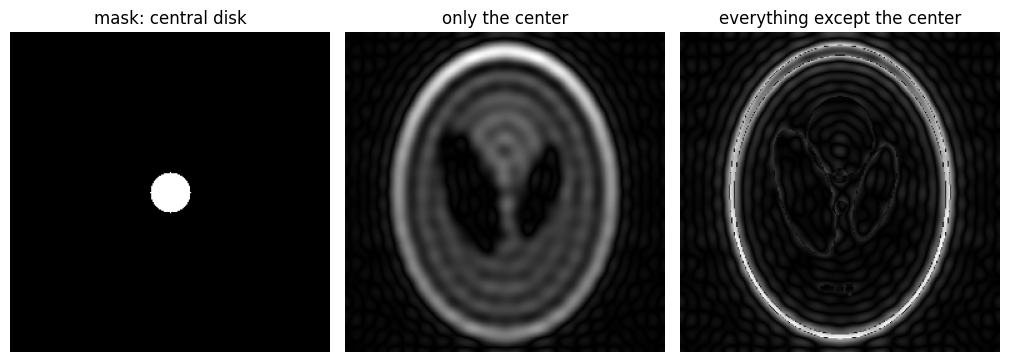

In [7]:
ky_grid, kx_grid = np.meshgrid(np.arange(N) - N // 2, np.arange(N) - N // 2, indexing="ij")
k_radius = np.sqrt(kx_grid**2 + ky_grid**2)

center_mask = k_radius <= 16
low_freq = ifft2c(kspace * center_mask)
high_freq = ifft2c(kspace * ~center_mask)

energy_center = np.sum(np.abs(kspace[center_mask]) ** 2) / np.sum(np.abs(kspace) ** 2)
print(f"Central disk: {center_mask.mean():.1%} of k-space points, {energy_center:.1%} of the signal energy")

show(
    [center_mask, np.abs(low_freq), np.abs(high_freq)],
    ["mask: central disk", "only the center", "everything except the center"],
)

- **The center of k-space** (low frequencies) holds about three quarters of the energy in just over 1% of the points. It sets the overall shapes, brightness and contrast, but the image is blurry and shows faint rings next to sharp edges (Gibbs ringing, caused by cutting k-space off abruptly).
- **The edges of k-space** (high frequencies) hold little energy but all the edges and fine detail.

This is why nearly every fast MRI method keeps the center of k-space fully sampled and saves time in the outer regions. You will use this idea in Notebook 2.

## 6. Resolution: how far out we sample

The finest stripe pattern we measure sets the finest detail we can see. So spatial resolution is set by how far out in k-space the scanner goes.

> **Predict:** We keep only a central square of k-space, 32, 64, 128 or all 256 points wide. How will the images differ?

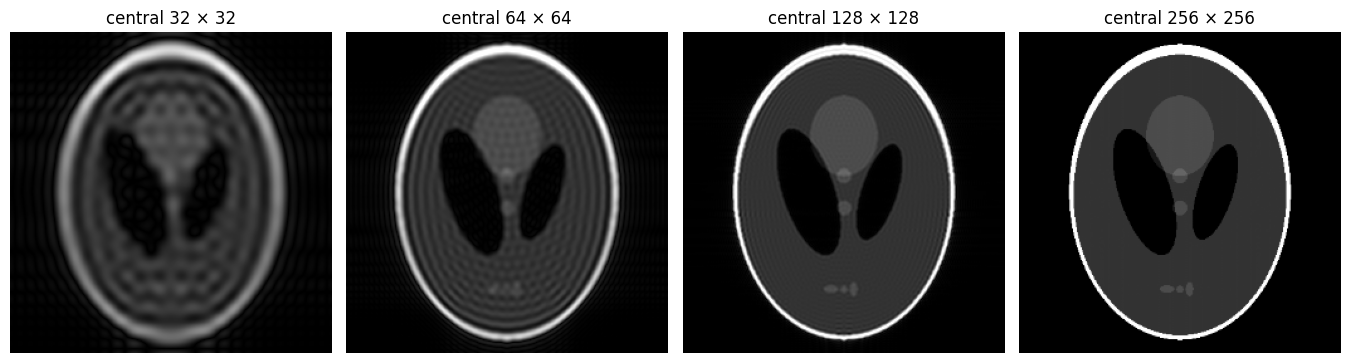

In [8]:
widths = [32, 64, 128, 256]
images = []
for w in widths:
    square = (np.abs(ky_grid) < w // 2) & (np.abs(kx_grid) < w // 2)
    images.append(np.abs(ifft2c(kspace * square)))

show(images, [f"central {w} × {w}" for w in widths], vmin=0, vmax=1)

Measuring a smaller part of k-space gives a lower-resolution image with more ringing, but the image still covers the whole object. Scanning only the central 64 × 64 points would take a quarter of the time, but small structures, such as the three small ellipses near the bottom, become hard to see. In clinical MRI, missing a small lesion is exactly the risk.

## 7. One bad sample ruins every pixel

Sometimes a single k-space sample is corrupted, for example by a static electricity discharge in the scanner room.

> **Predict:** We corrupt one k-space point out of 65,536. Will the error stay in a small region of the image, or will it appear everywhere?

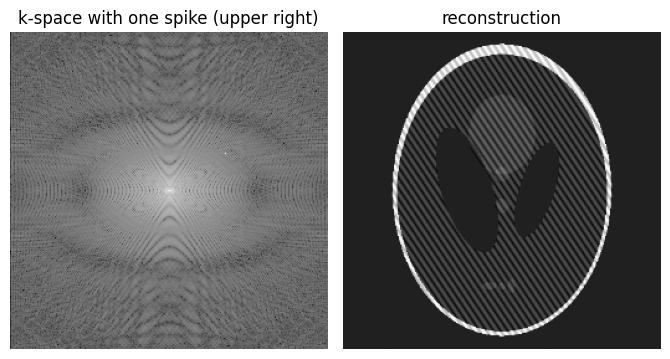

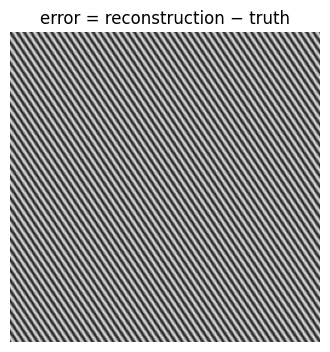

In [9]:
corrupted = kspace.copy()
corrupted[N // 2 - 30, N // 2 + 45] += 0.15 * N  # one spike, away from the center

spike_image = np.abs(ifft2c(corrupted))
error = (ifft2c(corrupted) - image).real
show([log_mag(corrupted), spike_image], ["k-space with one spike (upper right)", "reconstruction"])
show([error], ["error = reconstruction − truth"], vmin=-0.2, vmax=0.2)

One wrong point produces a stripe pattern across the entire image: the so-called herringbone or spike artifact seen on real scanners. This follows from Section 4: every k-space point contributes to every pixel.

The lesson for reconstruction: errors in k-space are global in the image. A reconstruction method that gets a few k-space values wrong will spread that error everywhere.

## 8. Looking ahead: why we want less k-space

MRI scan time is roughly proportional to the number of k-space lines measured. Measuring only every second line would halve the scan time. Here is what happens if we simply skip every second line and reconstruct with the inverse FFT:

In [ ]:
every_second_line = np.zeros((N, N), dtype=bool)
every_second_line[::2, :] = True  # keep lines 0, 2, 4, ... (vertical = phase-encode direction)

aliased = np.abs(ifft2c(kspace * every_second_line))
show(
    [every_second_line, aliased],
    ["mask: every 2nd line (2× faster)", "naive reconstruction"],
)

The object appears twice, overlapping itself: aliasing. The second copy is shifted by half the image height, so it wraps around the top and bottom edges. Halving the samples in one direction halves the field of view in that direction, so the parts that no longer fit wrap around.

Getting a good image from incomplete k-space is the whole problem of accelerated MRI reconstruction. In Notebook 2 you will try different undersampling patterns and see why *random* sampling produces noise-like artifacts instead of copies, which is the key idea behind compressed sensing and deep learning reconstruction.

## Exercises

Try each exercise yourself before opening the hint. Solutions are in `solutions/01_solutions.ipynb`.

### Exercise 1: half of k-space

Keep only the left half of k-space (`kx < 0`, everything else zero) and reconstruct. Compare the magnitude of the result with the original image. Is half of k-space enough? Why?

<details><summary>Hint</summary>

For a real-valued image, k-space has <b>conjugate symmetry</b>: the value at (ky, kx) is the complex conjugate of the value at (−ky, −kx). So one half already "knows" the other. Try rebuilding the missing half from that symmetry. Real MRI images have some phase, so scanners use a method called <i>partial Fourier</i> that measures a little over half.
</details>

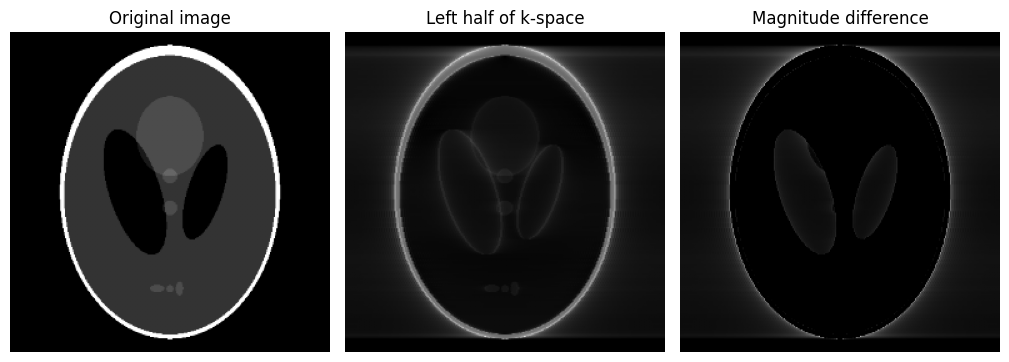

Fraction of k-space kept: 50.0%
Original image energy: 3852.9499
Reconstruction energy: 1364.9246


In [10]:
# Exercise 1: your code here

# Exercise 1: Keep only the left half of k-space

# Create a mask that keeps kx < 0
left_mask = kx_grid < 0

# Remove the right half of k-space
kspace_left = kspace * left_mask

# Reconstruct the image from the remaining data
recon_left = ifft2c(kspace_left)

# Display the original image and reconstructed magnitude
show(
    [
        image,
        np.abs(recon_left),
        np.abs(recon_left) - image
    ],
    [
        "Original image",
        "Left half of k-space",
        "Magnitude difference"
    ],
    vmin=0,
    vmax=1
)

# Print basic measurements
print(f"Fraction of k-space kept: {left_mask.mean():.1%}")
print(f"Original image energy: {np.sum(np.abs(image)**2):.4f}")
print(f"Reconstruction energy: {np.sum(np.abs(recon_left)**2):.4f}")


### Exercise 2: magnitude vs phase

1. Shift the phantom 20 pixels to the right with `np.roll(image, 20, axis=1)`. Compare the k-space magnitude and phase of the original and the shifted image. What changed?
2. Make a new k-space that has the magnitude of the phantom's k-space but random phase, and reconstruct it. Then try the opposite: phase of the phantom with constant magnitude. Which one keeps more of the structure?

<details><summary>Hint</summary>

The Fourier <b>shift theorem</b>: moving an object changes only the phase of its k-space (it adds a linear ramp), not the magnitude. For part 2, build the k-space with <code>np.abs(kspace) * np.exp(1j * phase)</code>.
</details>

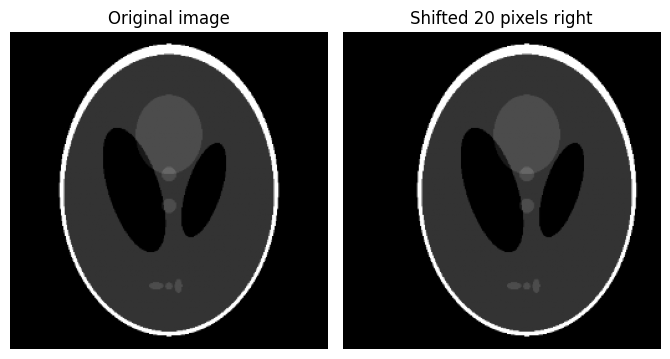

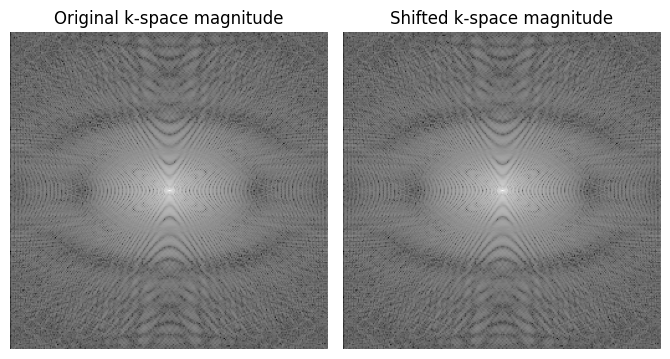

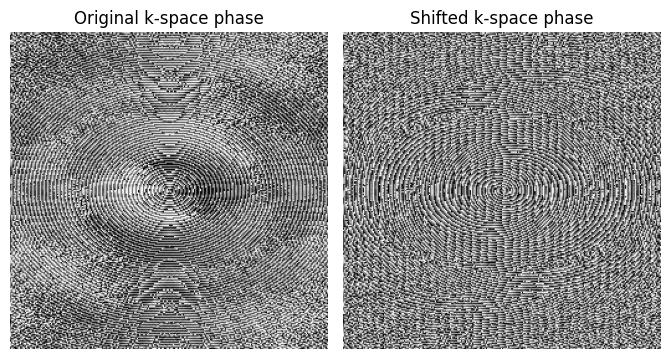

Maximum magnitude difference: 1.7763568394002505e-15


In [11]:
# Exercise 2: your code here

# Shift the image 20 pixels to the right
shifted_image = np.roll(image, 20, axis=1)

# Calculate k-space for the shifted image
kspace_shifted = fft2c(shifted_image)

# Compare original and shifted images, k-space magnitudes and phases
show(
    [image, shifted_image],
    ["Original image", "Shifted 20 pixels right"]
)

show(
    [log_mag(kspace), log_mag(kspace_shifted)],
    ["Original k-space magnitude", "Shifted k-space magnitude"]
)

show(
    [np.angle(kspace), np.angle(kspace_shifted)],
    ["Original k-space phase", "Shifted k-space phase"]
)

# Check the numerical difference in magnitudes
magnitude_difference = np.max(
    np.abs(np.abs(kspace) - np.abs(kspace_shifted))
)

print("Maximum magnitude difference:", magnitude_difference)


### Exercise 3: how much of the energy is in the center?

For disk radii 2, 4, 8, 16, 32, 64 and 128, compute the share of k-space energy inside the disk, and plot it against the radius. At what radius do you reach 95%? What does this suggest about where to spend scan time?

Radius   2: 39.70% of total energy
Radius   4: 48.69% of total energy
Radius   8: 59.96% of total energy
Radius  16: 75.47% of total energy
Radius  32: 90.54% of total energy
Radius  64: 97.43% of total energy
Radius 128: 99.64% of total energy

95% of energy is reached at radius 64.


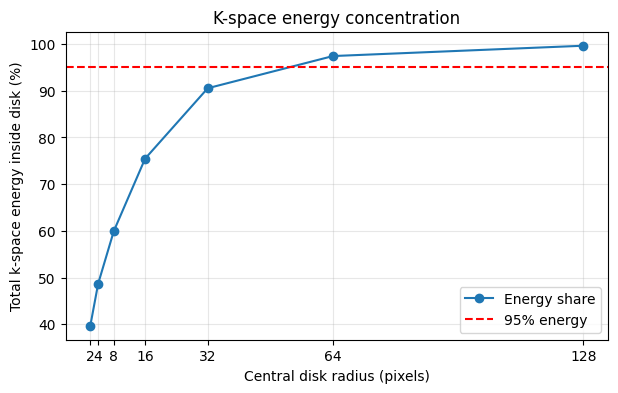

In [12]:
# Exercise 3: your code here

# Exercise 3: Energy inside central k-space disks

radii = [2, 4, 8, 16, 32, 64, 128]
total_energy = np.sum(np.abs(kspace)**2)

energy_shares = []

for r in radii:
    # Create a circular mask centered at k-space origin
    disk_mask = np.sqrt(kx_grid**2 + ky_grid**2) <= r

    # Calculate the fraction of total energy inside the disk
    energy_inside = np.sum(np.abs(kspace[disk_mask])**2)
    share = energy_inside / total_energy
    energy_shares.append(share)

    print(f"Radius {r:3d}: {share:.2%} of total energy")

# Find the first tested radius that reaches 95%
r95 = next(
    (r for r, share in zip(radii, energy_shares) if share >= 0.95),
    None
)

if r95 is not None:
    print(f"\n95% of energy is reached at radius {r95}.")
else:
    print("\n95% of energy was not reached at the tested radii.")

# Plot energy share against radius
plt.figure(figsize=(7, 4))
plt.plot(radii, np.array(energy_shares) * 100, "o-", label="Energy share")
plt.axhline(95, color="red", linestyle="--", label="95% energy")
plt.xlabel("Central disk radius (pixels)")
plt.ylabel("Total k-space energy inside disk (%)")
plt.title("K-space energy concentration")
plt.xticks(radii)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


### Exercise 4: rotation

Rotate the phantom by 30° with `rotate(image, 30)` and compute its k-space. How does the k-space magnitude change? Explain the result using Section 4.

Radius   2: 39.70% of total energy
Radius   4: 48.69% of total energy
Radius   8: 59.96% of total energy
Radius  16: 75.47% of total energy
Radius  32: 90.54% of total energy
Radius  64: 97.43% of total energy
Radius 128: 99.64% of total energy

95% of energy is reached at radius 64.


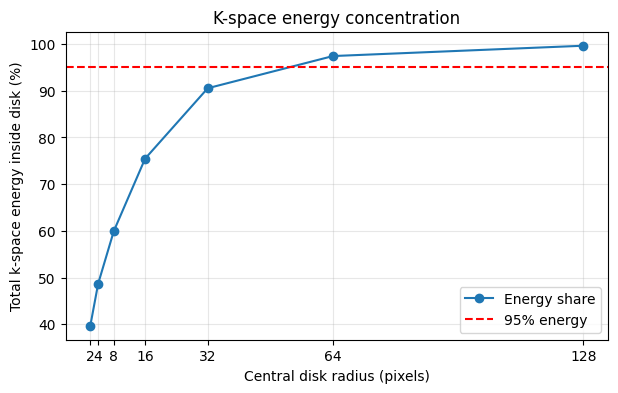

In [13]:
# Exercise 4: your code here

# Exercise 3: Energy inside central k-space disks

radii = [2, 4, 8, 16, 32, 64, 128]
total_energy = np.sum(np.abs(kspace)**2)

energy_shares = []

for r in radii:
    # Create a circular mask centered at k-space origin
    disk_mask = np.sqrt(kx_grid**2 + ky_grid**2) <= r

    # Calculate the fraction of total energy inside the disk
    energy_inside = np.sum(np.abs(kspace[disk_mask])**2)
    share = energy_inside / total_energy
    energy_shares.append(share)

    print(f"Radius {r:3d}: {share:.2%} of total energy")

# Find the first tested radius that reaches 95%
r95 = next(
    (r for r, share in zip(radii, energy_shares) if share >= 0.95),
    None
)

if r95 is not None:
    print(f"\n95% of energy is reached at radius {r95}.")
else:
    print("\n95% of energy was not reached at the tested radii.")

# Plot energy share against radius
plt.figure(figsize=(7, 4))
plt.plot(radii, np.array(energy_shares) * 100, "o-", label="Energy share")
plt.axhline(95, color="red", linestyle="--", label="95% energy")
plt.xlabel("Central disk radius (pixels)")
plt.ylabel("Total k-space energy inside disk (%)")
plt.title("K-space energy concentration")
plt.xticks(radii)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Summary

- An MRI scanner measures k-space, the 2D Fourier transform of the image. With full k-space, the inverse FFT reconstructs the image exactly.
- Each k-space point is a stripe pattern over the whole image: its distance from the center sets the stripe frequency, its direction sets the orientation.
- The center of k-space holds most of the energy and the contrast; the edges hold edges and fine detail. How far out you sample sets the resolution.
- Every k-space point affects every pixel, so errors in k-space spread across the whole image.
- Measuring less k-space makes scans faster but causes aliasing, which is the problem the rest of this module solves.

**Next:** Notebook 2, *Undersampling and aliasing*.

## References

1. Shepp, L. A., & Logan, B. F. (1974). The Fourier reconstruction of a head section. *IEEE Transactions on Nuclear Science*, 21(3), 21–43.
2. Nishimura, D. G. (2010). *Principles of Magnetic Resonance Imaging*. Stanford University.
3. Brown, R. W., Cheng, Y.-C. N., Haacke, E. M., Thompson, M. R., & Venkatesan, R. (2014). *Magnetic Resonance Imaging: Physical Properties and Sequence Design* (2nd ed.). Wiley.
4. van der Walt, S., et al. (2014). scikit-image: image processing in Python. *PeerJ*, 2, e453.

---
*Text and figures: CC-BY 4.0. Code: MIT License.*